In [1]:
# importing libraries
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [2]:
waves = pd.read_csv('waves_2023.txt', sep=r'\s+')

In [3]:
waves.describe()

,YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,TIDE
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.000000,17285.0,17285.0,17285.0
mean,2023.0,6.526063,15.800579,11.499277,40.985594,999.0,99.0,99.0,1.083535,12.161879,6.813054,234.556205,9999.0,999.0,17.196535,999.0,99.0,99.0
std,0.0,3.467253,8.817920,6.925343,15.007646,0.0,0.0,0.0,2.296129,4.165737,2.803208,49.429981,0.0,0.0,2.564664,0.0,0.0,0.0
min,2023.0,1.000000,1.000000,0.000000,0.000000,999.0,99.0,99.0,0.330000,2.860000,3.420000,10.000000,9999.0,999.0,11.800000,999.0,99.0,99.0
25%,2023.0,4.000000,8.000000,5.000000,26.000000,999.0,99.0,99.0,0.730000,9.090000,5.500000,179.000000,9999.0,999.0,14.600000,999.0,99.0,99.0
50%,2023.0,6.000000,16.000000,11.000000,26.000000,999.0,99.0,99.0,0.880000,12.500000,6.360000,263.000000,9999.0,999.0,17.500000,999.0,99.0,99.0
75%,2023.0,10.000000,23.000000,18.000000,56.000000,999.0,99.0,99.0,1.140000,14.290000,7.550000,271.000000,9999.0,999.0,19.400000,999.0,99.0,99.0
max,2023.0,12.000000,31.000000,23.000000,56.000000,999.0,99.0,99.0,99.000000,99.000000,99.000000,999.000000,9999.0,999.0,23.900000,999.0,99.0,99.0


In [4]:
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves.describe()

,YY,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000
mean,2023.0,6.526063,15.800579,11.499277,40.985594,1.083535,12.161879,6.813054,234.556205,17.196535
std,0.0,3.467253,8.817920,6.925343,15.007646,2.296129,4.165737,2.803208,49.429981,2.564664
min,2023.0,1.000000,1.000000,0.000000,0.000000,0.330000,2.860000,3.420000,10.000000,11.800000
25%,2023.0,4.000000,8.000000,5.000000,26.000000,0.730000,9.090000,5.500000,179.000000,14.600000
50%,2023.0,6.000000,16.000000,11.000000,26.000000,0.880000,12.500000,6.360000,263.000000,17.500000
75%,2023.0,10.000000,23.000000,18.000000,56.000000,1.140000,14.290000,7.550000,271.000000,19.400000
max,2023.0,12.000000,31.000000,23.000000,56.000000,99.000000,99.000000,99.000000,999.000000,23.900000


In [5]:
# WVHT = Wave Height (m)
# DPD = Dominant wave period (seconds)
# APD = Average wave period (seconds)
# MWD = The direction from which the waves at the dominant period (DPD) are coming
# WTMP = Sea surface temperature (Celsius)

waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

In [6]:
wavesML = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)
waves.describe()

,YY,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
count,17276.0,17276.000000,17276.000000,17276.000000,17276.000000,17276.000000,17276.000000,17276.000000,17276.000000,17276.000000
mean,2023.0,6.524427,15.801517,11.499479,40.996527,1.032525,12.116640,6.765029,234.157965,17.195294
std,0.0,3.467398,8.817744,6.925483,15.000434,0.526637,3.664928,1.852623,46.260000,2.564729
min,2023.0,1.000000,1.000000,0.000000,26.000000,0.330000,2.860000,3.420000,10.000000,11.800000
25%,2023.0,4.000000,8.000000,5.000000,26.000000,0.730000,9.090000,5.500000,179.000000,14.600000
50%,2023.0,6.000000,16.000000,11.000000,26.000000,0.880000,12.500000,6.360000,263.000000,17.500000
75%,2023.0,10.000000,23.000000,18.000000,56.000000,1.140000,14.290000,7.550000,271.000000,19.400000
max,2023.0,12.000000,31.000000,23.000000,56.000000,5.130000,25.000000,15.790000,306.000000,23.900000


In [7]:
wavesML

,WVHT,DPD,APD,MWD,WTMP
0,1.12,12.50,7.69,269,15.3
1,1.16,11.76,7.34,272,15.3
2,1.20,12.50,7.08,268,15.3
3,1.25,10.53,7.33,268,15.4
4,1.27,10.53,7.57,268,15.5
...,...,...,...,...,...
17280,2.01,14.29,11.19,270,16.7
17281,1.75,15.38,10.37,267,16.7
17282,1.79,13.33,10.50,268,16.8
17283,1.66,14.29,10.32,271,16.8


In [8]:
df_X = wavesML.drop(['WVHT'],axis=1).to_numpy() #want to predict wave height so drop it from x
df_y = wavesML['WVHT'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10)

In [9]:
from sklearn.ensemble import RandomForestRegressor
regRF = RandomForestRegressor(n_estimators=100)
regRF = regRF.fit(X_train, y_train)
yPred = regRF.predict(X_val)
mean_squared_error(yPred,y_val)

0.0819181177014041

In [10]:
# fit with decision tree regressor and random forest regressor with 25 trees and compare with linear model

In [11]:
regRF25 = RandomForestRegressor(n_estimators=25)
regRF25 = regRF25.fit(X_train, y_train)
yPred = regRF25.predict(X_val)
mean_squared_error(yPred,y_val)

0.08236108148383782

In [12]:
yPred_test = regRF25.predict(X_test)
mean_squared_error(yPred_test,y_test)

0.08190828581597222

In [13]:
from sklearn.tree import DecisionTreeRegressor

dtr = DecisionTreeRegressor()
dtr = dtr.fit(X_train, y_train)
dtryPred = dtr.predict(X_val)
mean_squared_error(dtryPred,y_val)

0.14323848874598072

In [14]:
dtryPred_test = dtr.predict(X_test)
mean_squared_error(dtryPred_test,y_test)

0.1436617621527778

In [15]:
linear_reg = linear_model.LinearRegression()
linear_reg.fit(df_X,df_y)
rYPred= linear_reg.predict(X_val)
mean_squared_error(rYPred,y_val)

0.18916647132752487

In [16]:
ryPred_test = linear_reg.predict(X_test)
mean_squared_error(ryPred_test,y_test)

0.20193301129925517

In [17]:
# The random forest model more accurately predicts the data, its MSE is lower than that of the linear model and decision tree model

In [18]:
# The linear regression model uses the OLS cost funtion
# The decision tree regressor uses squared error 
# The random forest regressor uses squared error
# I did not optimize a hyperparameter in these models.

In [19]:
# Redoing splits, I got simmilar answers for both, within a 100th for the forest model and within a 10th for the linear regression/tree models

In [20]:
# Train on 2,10,25,50,100,250,500,1000 trees

In [34]:
m2 = RandomForestRegressor(n_estimators=2)
m2 = m2.fit(X_train, y_train)
yPred2 = m2.predict(X_val)
mse2train = mean_squared_error(yPred2,y_val)

yPred_test2 = m2.predict(X_test)
mse2test = mean_squared_error(yPred_test2,y_test)

In [35]:
m10 = RandomForestRegressor(n_estimators=10)
m10 = m10.fit(X_train, y_train)
yPred10 = m10.predict(X_val)
mse10train = mean_squared_error(yPred10,y_val)

yPred_test10 = m10.predict(X_test)
mse10test = mean_squared_error(yPred_test10,y_test)

In [45]:
m25 = RandomForestRegressor(n_estimators=25)
m25 = m25.fit(X_train, y_train)
yPred25 = m25.predict(X_val)
mse25train = mean_squared_error(yPred25,y_val)


yPred_test25 = m25.predict(X_test)
mse25test = mean_squared_error(yPred_test25,y_test)

In [46]:
m50 = RandomForestRegressor(n_estimators=50)
m50 = m50.fit(X_train, y_train)
yPred50 = m50.predict(X_val)
mse50train = mean_squared_error(yPred50,y_val)


yPred_test50 = m50.predict(X_test)
mse50test = mean_squared_error(yPred_test50,y_test)

In [47]:
m100 = RandomForestRegressor(n_estimators=100)
m100 = m100.fit(X_train, y_train)
yPred100 = m100.predict(X_val)
mse100train = mean_squared_error(yPred100,y_val)

yPred_test100 = m100.predict(X_test)
mse100test = mean_squared_error(yPred_test100,y_test)

In [53]:
m250 = RandomForestRegressor(n_estimators=250)
m250 = m250.fit(X_train, y_train)
yPred250 = m250.predict(X_val)
mse250train = mean_squared_error(yPred250,y_val)

yPred_test250 = m250.predict(X_test)
mse250test = mean_squared_error(yPred_test250,y_test)

In [54]:
m500 = RandomForestRegressor(n_estimators=500)
m500 = m500.fit(X_train, y_train)
yPred500 = m500.predict(X_val)
mse500train = mean_squared_error(yPred500,y_val)

yPred_test500 = m500.predict(X_test)
mse500test = mean_squared_error(yPred_test500,y_test)

In [55]:
m1000 = RandomForestRegressor(n_estimators=1000)
m1000 = m1000.fit(X_train, y_train)
yPred1000 = m1000.predict(X_val)
mse1000train = mean_squared_error(yPred1000,y_val)

yPred_test1000 = m1000.predict(X_test)
mse1000test = mean_squared_error(yPred_test1000,y_test)

In [58]:
a = {
    "MSE Training": [mse2train, mse10train, mse25train, mse50train, mse100train, mse250train, mse500train, mse1000train],
    "MSE Testing": [mse2test, mse10test, mse25test, mse50test, mse100test, mse250test, mse500test, mse1000test],
    "Number of Trees": ['2', '10', '25', '50', '100', '250', '500', '1000'] 
}

MSEdf = pd.DataFrame(a)

print(MSEdf)

   MSE Training  MSE Testing Number of Trees
0      0.116896     0.121279               2
1      0.085998     0.088948              10
2      0.082014     0.083185              25
3      0.082063     0.082562              50
4      0.081799     0.081053             100
5      0.081001     0.079294             250
6      0.080171     0.079205             500
7      0.080647     0.079189            1000


Text(0.5, 1.0, 'MSE of training and testing data as forest model increases in complexity')

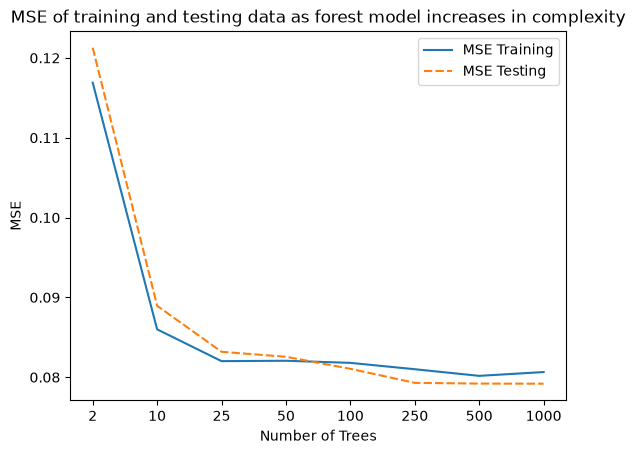

In [81]:
xlabels = (2,10,25,50,100,250,500,1000)
xticks = (0,1,2,3,4,5,6,7)
p = sns.lineplot(data=MSEdf).set_xticks(xticks, labels=xlabels)
plt.xlabel('Number of Trees')
plt.ylabel('MSE')
plt.title("MSE of training and testing data as forest model increases in complexity")

In [ ]:
# There does not seem to be evidence of overfitting